In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# index_col=0 uses the "Unnamed: 0" column as the row index (it was just a row number)
df = pd.read_csv("../data/raw/cs-training.csv", index_col=0)
target = "SeriousDlqin2yrs"

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


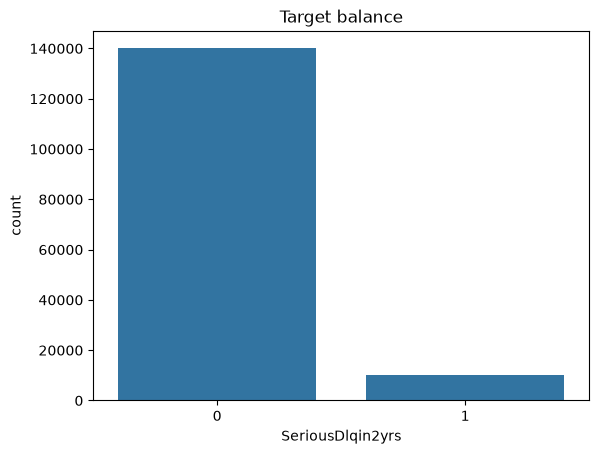

In [3]:
print(df[target].value_counts())
print(df[target].value_counts(normalize=True))

sns.countplot(x=target, data=df)
plt.title("Target balance")
plt.show()

In [4]:
cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome"]
df[cols].quantile([0.01, 0.50, 0.99, 0.999]).T

,0.010,0.500,0.990,0.999
RevolvingUtilizationOfUnsecuredLines,0.0,0.154181,1.092956,1571.006
age,24.0,52.000000,87.000000,94.000
DebtRatio,0.0,0.366508,4979.040000,10613.074
MonthlyIncome,0.0,5400.000000,25000.000000,78395.748


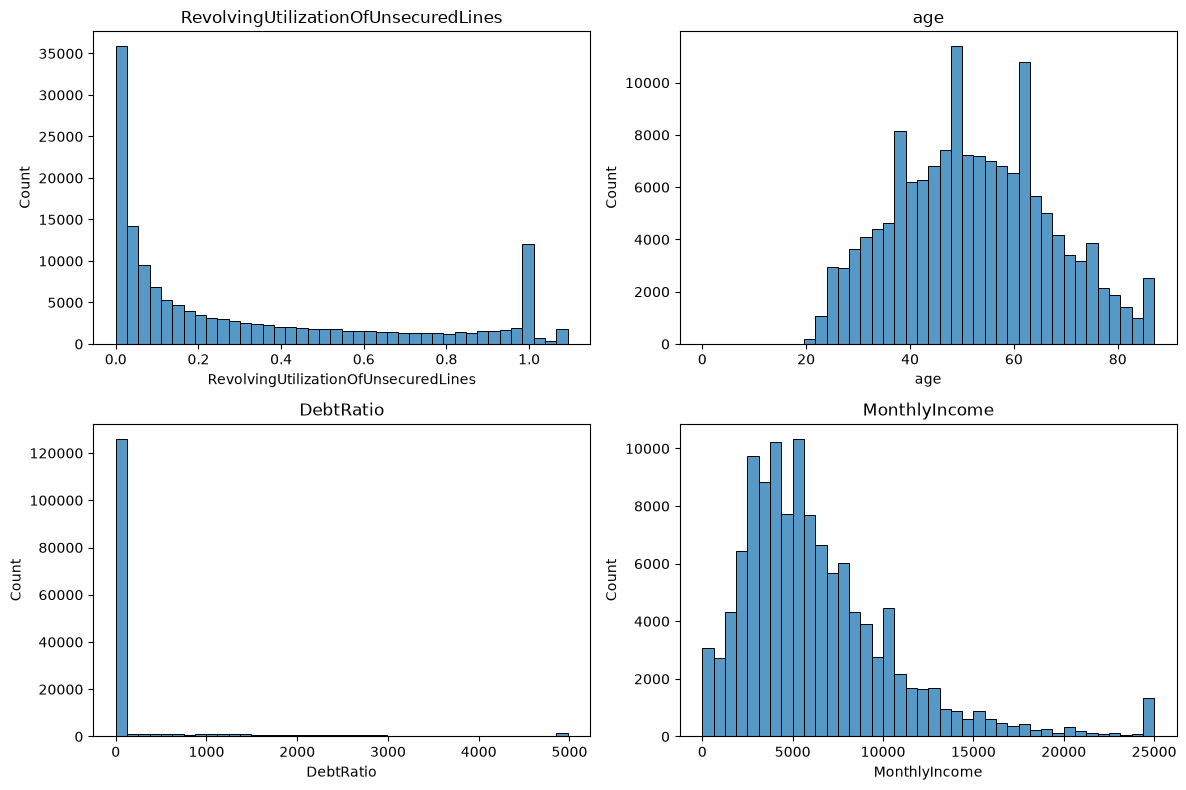

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cols):
    upper = df[col].quantile(0.99)
    sns.histplot(df[col].clip(upper=upper), bins=40, ax=ax)   # clip affects the plot only, not df
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [6]:
age_bins = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 120])
df.groupby(age_bins, observed=True)[target].mean()

age
(0, 25]      0.111662
(25, 35]     0.111225
(35, 45]     0.088132
(45, 55]     0.075933
(55, 65]     0.045830
(65, 120]    0.024127
Name: SeriousDlqin2yrs, dtype: float64

In [7]:
late = df["NumberOfTimes90DaysLate"].clip(upper=5)   # clip for grouping only
df.groupby(late)[target].agg(["mean", "count"])

,mean,count
NumberOfTimes90DaysLate,,
0,0.046265,141662
1,0.336639,5243
2,0.499035,1555
3,0.577211,667
4,0.670103,291
5,0.603093,582


In [8]:
df.corr(method="spearman")[target].drop(target).sort_values()

age                                    -0.117034
MonthlyIncome                          -0.066980
NumberOfOpenCreditLinesAndLoans        -0.038587
NumberRealEstateLoansOrLines           -0.034118
DebtRatio                               0.020597
NumberOfDependents                      0.045972
RevolvingUtilizationOfUnsecuredLines    0.240378
NumberOfTime30-59DaysPastDueNotWorse    0.257411
NumberOfTime60-89DaysPastDueNotWorse    0.277111
NumberOfTimes90DaysLate                 0.342349
Name: SeriousDlqin2yrs, dtype: float64